# **Step No.1: Load Data**

## Load Data and Take Sample

In [33]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_performance.csv")
print("Total shape:", df.shape)

# Small sample for charts (1 million rows are slow)
df_sample = df.sample(50000, random_state=42)
print("Sample shape:", df_sample.shape)

Total shape: (1000000, 6)
Sample shape: (50000, 6)


# Check Missing Values and Duplicates

In [34]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

# Duplicate student_id
print("\nDuplicate IDs:", df["student_id"].duplicated().sum())

# Duplicate rows (ignoring ID)
dup = df.drop(columns="student_id").duplicated().sum()
print("Duplicate rows (ignoring ID):", dup)

Missing values:
student_id                 0
weekly_self_study_hours    0
attendance_percentage      0
class_participation        0
total_score                0
grade                      0
dtype: int64

Duplicate IDs: 0
Duplicate rows (ignoring ID): 17868


# Check Value Ranges

In [35]:
# Min and max of each column
print(df.describe().T[["min", "max", "mean"]])

# Find invalid values
print("\nAttendance above 100:", (df["attendance_percentage"] > 100).sum())
print("Attendance below 0:", (df["attendance_percentage"] < 0).sum())
print("Participation above 10:", (df["class_participation"] > 10).sum())
print("Score above 100:", (df["total_score"] > 100).sum())

                          min        max           mean
student_id                1.0  1000000.0  500000.500000
weekly_self_study_hours   0.0       40.0      15.029127
attendance_percentage    50.0      100.0      84.711046
class_participation       0.0       10.0       5.985203
total_score               9.4      100.0      84.283845

Attendance above 100: 0
Attendance below 0: 0
Participation above 10: 0
Score above 100: 0


# Check Clipping (Capped Values)

In [36]:
total = len(df)

full_marks = (df["total_score"] == 100).sum()
print(f"Score = 100: {full_marks} students ({full_marks/total*100:.1f}%)")

zero_study = (df["weekly_self_study_hours"] == 0).sum()
print(f"Study hours = 0: {zero_study} students ({zero_study/total*100:.1f}%)")

zero_part = (df["class_participation"] == 0).sum()
print(f"Participation = 0: {zero_part} students ({zero_part/total*100:.2f}%)")

Score = 100: 268121 students (26.8%)
Study hours = 0: 16492 students (1.6%)
Participation = 0: 1420 students (0.14%)


# Check Grade vs Score Match

In [37]:
# Min and max score for each grade
print(df.groupby("grade")["total_score"].agg(["min", "max", "mean", "count"]))

        min    max       mean   count
grade                                
A      85.0  100.0  96.042375  548644
B      70.0   85.0  77.946590  258174
C      55.0   70.0  63.564524  141980
D      40.0   55.0  49.380346   44998
F       9.4   40.0  35.474146    6204


# Set Grade Order

In [38]:
# Make grade an ordered category (A is best)
grade_order = ["F", "D", "C", "B", "A"]
df["grade"] = pd.Categorical(df["grade"], categories=grade_order, ordered=True)

print(df["grade"].value_counts().sort_index())

grade
F      6204
D     44998
C    141980
B    258174
A    548644
Name: count, dtype: int64


# Drop Unneeded Column

In [39]:
# student_id is not useful for analysis
df_clean = df.drop(columns="student_id")
df_clean.head()

,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,18.5,95.6,3.8,97.9,A
1,14.0,80.0,2.5,83.9,B
2,19.5,86.3,5.3,100.0,A
3,25.7,70.2,7.0,100.0,A
4,13.4,81.9,6.9,92.0,A


# Check Correlation

In [40]:
corr = df_clean.drop(columns="grade").corr()
print(corr.round(3))

                         weekly_self_study_hours  attendance_percentage  \
weekly_self_study_hours                    1.000                 -0.001   
attendance_percentage                     -0.001                  1.000   
class_participation                        0.001                 -0.000   
total_score                                0.812                 -0.001   

                         class_participation  total_score  
weekly_self_study_hours                0.001        0.812  
attendance_percentage                 -0.000       -0.001  
class_participation                    1.000        0.001  
total_score                            0.001        1.000  


# **Step No.2:EDA (Charts)**

# Setup for Charts

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Use sample for faster charts
df_sample = df_clean.sample(50000, random_state=42)

# Histogram of Total Score

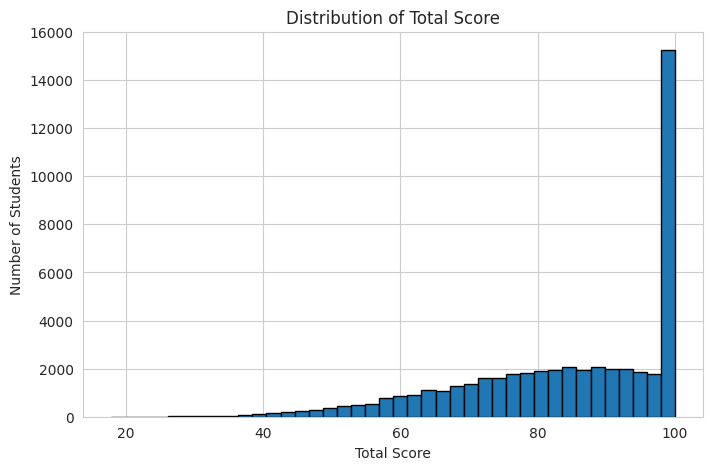

In [42]:
plt.hist(df_sample["total_score"], bins=40, edgecolor="black")
plt.title("Distribution of Total Score")
plt.xlabel("Total Score")
plt.ylabel("Number of Students")
plt.show()

Left-skewed, with a big spike at 100 (27% of students). This is clipping, not a natural peak

# Grade Count Chart

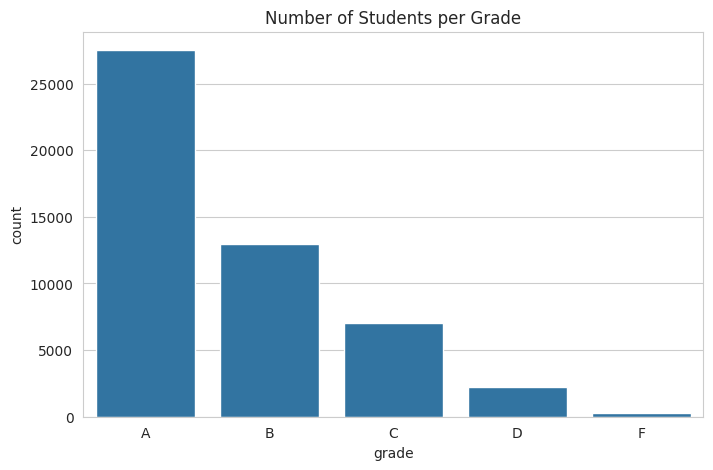

In [43]:
order = ["A", "B", "C", "D", "F"]
sns.countplot(data=df_sample, x="grade", order=order)
plt.title("Number of Students per Grade")
plt.show()

A is 55%, F is only 0.6%. The data is imbalanced

# Study Hours vs Score

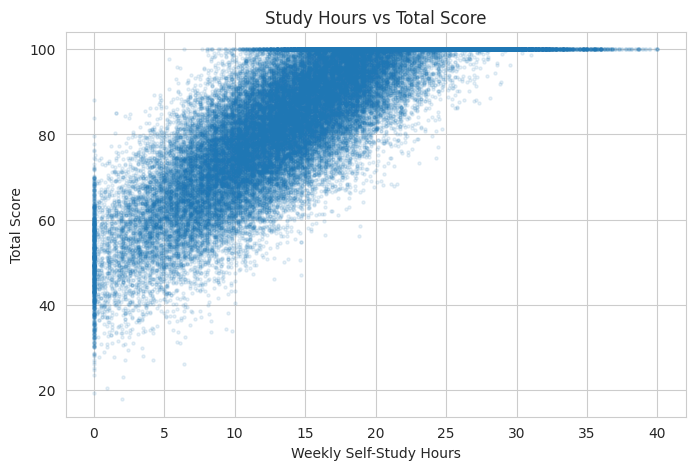

In [44]:
plt.scatter(df_sample["weekly_self_study_hours"],
            df_sample["total_score"], alpha=0.1, s=5)
plt.title("Study Hours vs Total Score")
plt.xlabel("Weekly Self-Study Hours")
plt.ylabel("Total Score")
plt.show()

Each extra hour adds about 2 marks, then the score flattens at 100 around 23 to 25 hours

# Attendance vs Score

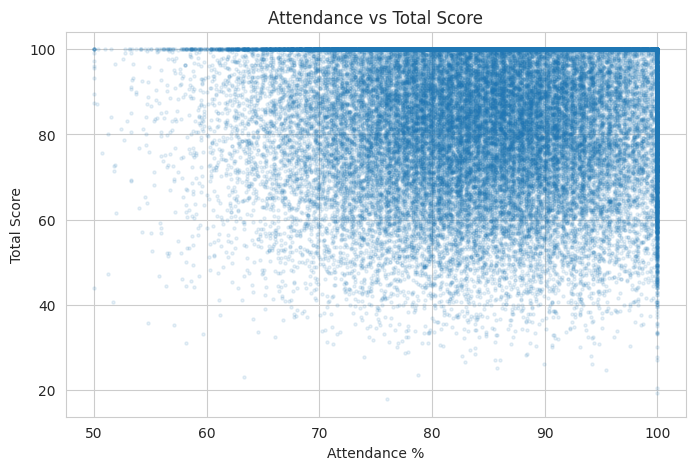

In [45]:
plt.scatter(df_sample["attendance_percentage"],
            df_sample["total_score"], alpha=0.1, s=5)
plt.title("Attendance vs Total Score")
plt.xlabel("Attendance %")
plt.ylabel("Total Score")
plt.show()

Flat cloud, no pattern. Students with 60% and 100% attendance have the same average score (84.3)

# Participation vs Score

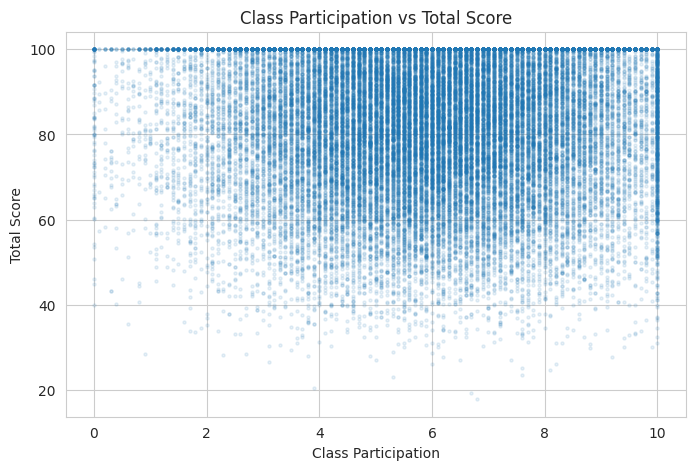

In [46]:
plt.scatter(df_sample["class_participation"],
            df_sample["total_score"], alpha=0.1, s=5)
plt.title("Class Participation vs Total Score")
plt.xlabel("Class Participation")
plt.ylabel("Total Score")
plt.show()

Same result, no effect

# Boxplot of Study Hours by Grade

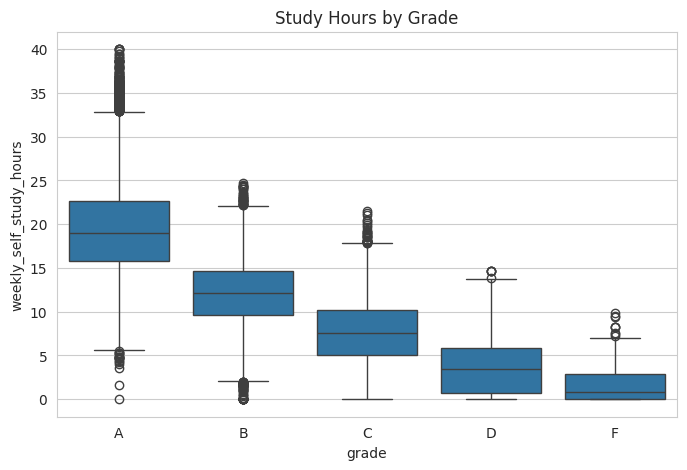

In [47]:
sns.boxplot(data=df_sample, x="grade", y="weekly_self_study_hours",
            order=["A", "B", "C", "D", "F"])
plt.title("Study Hours by Grade")
plt.show()

Study hours rise with grade (median F: 0.5 hours, A: 19 hours)

# Correlation Heatmap

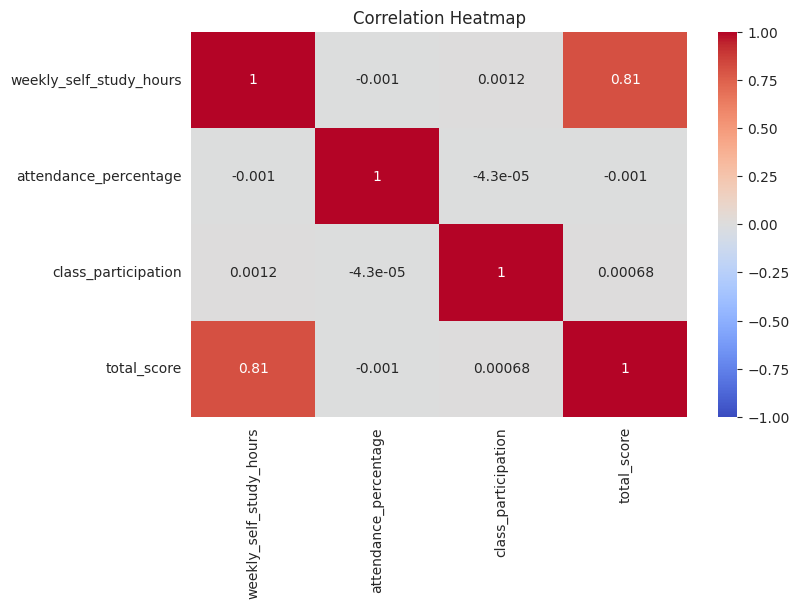

In [48]:
corr = df_clean.drop(columns="grade").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

Study hours correlate 0.81 with score, the other two are about 0

# Average Score by Study Hours Group

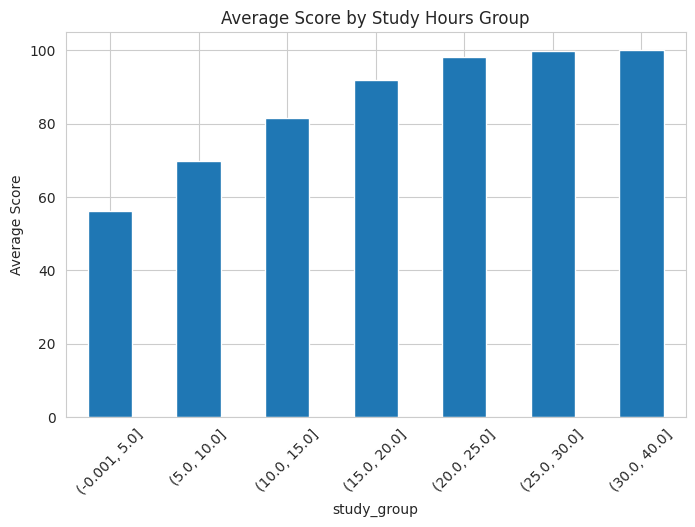

In [49]:
df_sample = df_sample.copy()
df_sample["study_group"] = pd.cut(
    df_sample["weekly_self_study_hours"],
    bins=[0, 5, 10, 15, 20, 25, 30, 40],
    include_lowest=True
)

avg = df_sample.groupby("study_group", observed=True)["total_score"].mean()
avg.plot(kind="bar")
plt.title("Average Score by Study Hours Group")
plt.ylabel("Average Score")
plt.xticks(rotation=45)
plt.show()

**My observation:**
- Average score rises as study hours increase, but the growth slows down and then stops.
- The first four bars rise quickly (about 56, 70, 81, 92). After 20 hours the bars flatten near 100.
- 99.8% of students who study more than 30 hours score exactly 100, which confirms that scores are capped at 100.

**Conclusion:** The relationship is linear at first, then flat. A straight-line model will struggle near the top, so Random Forest may fit better.

# **Step No.3:Feature Engineering (Data Preparation)**

# Define Target and Features

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Target = what we want to predict
target = "total_score"

# Features = inputs the model will use
# NOTE: "grade" is NOT included because it is made from total_score (data leakage)
features = ["weekly_self_study_hours", "attendance_percentage", "class_participation"]

X = df_clean[features]
y = df_clean[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000000, 3)
y shape: (1000000,)


# Check Features

In [51]:
X.head()

,weekly_self_study_hours,attendance_percentage,class_participation
0,18.5,95.6,3.8
1,14.0,80.0,2.5
2,19.5,86.3,5.3
3,25.7,70.2,7.0
4,13.4,81.9,6.9


# Split into Train and Test

In [52]:
# Drop the few missing values first before splitting
df_clean = df_clean.dropna(subset=features + [target, "grade"])

X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=df_clean["grade"]
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (800000, 3)
Test size: (200000, 3)


# Check the Split is Fair

In [53]:
print("Average score in train:", round(y_train.mean(), 2))
print("Average score in test:", round(y_test.mean(), 2))

print("\nGrade share in train:")
print(df_clean.loc[y_train.index, "grade"].value_counts(normalize=True).round(3))

print("\nGrade share in test:")
print(df_clean.loc[y_test.index, "grade"].value_counts(normalize=True).round(3))

Average score in train: 84.29
Average score in test: 84.28

Grade share in train:
grade
A    0.549
B    0.258
C    0.142
D    0.045
F    0.006
Name: proportion, dtype: float64

Grade share in test:
grade
A    0.549
B    0.258
C    0.142
D    0.045
F    0.006
Name: proportion, dtype: float64


# Create a New Feature (Optional)

In [54]:
# Copy the data so the original stays unchanged
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Score rises with study hours but curves near the top,
# so we add study hours squared to help a straight-line model
X_train_fe["study_hours_squared"] = X_train_fe["weekly_self_study_hours"] ** 2
X_test_fe["study_hours_squared"] = X_test_fe["weekly_self_study_hours"] ** 2

print(X_train_fe.columns.tolist())

['weekly_self_study_hours', 'attendance_percentage', 'class_participation', 'study_hours_squared']


# Baseline Model (Always Guess the Average)

In [55]:
# The simplest "model": predict the training average for every student
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 12.92
Baseline RMSE: 15.44


# **Step No.4: Build and Compare Models**

# Imports and Evaluation Function

In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

results = {}

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    results[name] = {"MAE": round(mae, 2), "RMSE": round(rmse, 2), "R2": round(r2, 3)}
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}, R2={r2:.3f}")

# Save the baseline from Step 5 for comparison
evaluate("Baseline (average)", y_test, baseline_pred)

Baseline (average): MAE=12.92, RMSE=15.44, R2=-0.000


# Linear Regression

In [57]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
evaluate("Linear Regression", y_test, lr_pred)

Linear Regression: MAE=7.18, RMSE=9.02, R2=0.659


# Linear Regression Coefficients

In [58]:
coef = pd.Series(lr.coef_, index=features)
print(coef.round(3))
print("Intercept:", round(lr.intercept_, 2))

print("\nPredictions above 100:", (lr_pred > 100).sum())
print("Highest prediction:", lr_pred.max().round(1))

weekly_self_study_hours    1.817
attendance_percentage     -0.000
class_participation       -0.002
dtype: float64
Intercept: 57.01

Predictions above 100: 21661
Highest prediction: 129.7


# Linear Regression with Squared Feature

In [59]:
lr_fe = LinearRegression()
lr_fe.fit(X_train_fe, y_train)

lr_fe_pred = lr_fe.predict(X_test_fe)
evaluate("Linear Regression + squared", y_test, lr_fe_pred)

Linear Regression + squared: MAE=6.33, RMSE=8.30, R2=0.711


# Random Forest

In [60]:
# Use a 200,000 row sample of the training data so it runs faster in Colab
X_rf = X_train.sample(200000, random_state=42)
y_rf = y_train.loc[X_rf.index]

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_rf, y_rf)

rf_pred = rf.predict(X_test)
evaluate("Random Forest", y_test, rf_pred)
print("Highest prediction:", rf_pred.max().round(1))

Random Forest: MAE=6.14, RMSE=8.25, R2=0.715
Highest prediction: 100.0


# Feature Importance

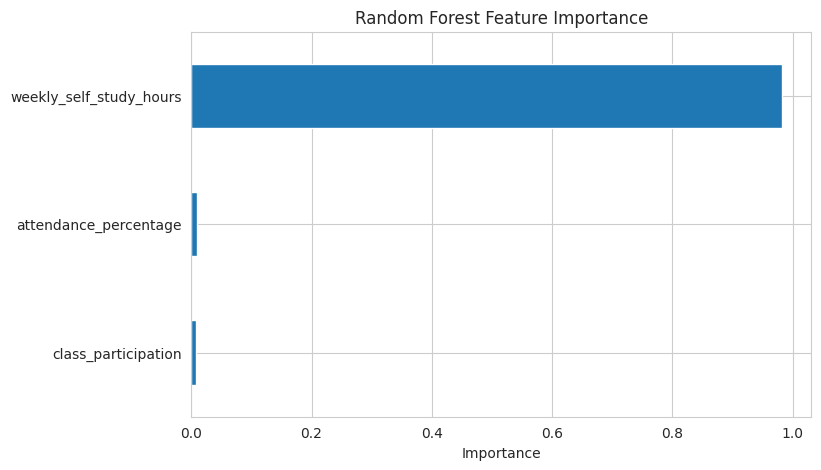

weekly_self_study_hours    0.9816
attendance_percentage      0.0104
class_participation        0.0080
dtype: float64


In [32]:
importance = pd.Series(rf.feature_importances_, index=features).sort_values()

importance.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

print(importance.sort_values(ascending=False).round(4))

# Compare All Models

In [61]:
comparison = pd.DataFrame(results).T
comparison

,MAE,RMSE,R2
Baseline (average),12.92,15.44,-0.000
Linear Regression,7.18,9.02,0.659
Linear Regression + squared,6.33,8.30,0.711
Random Forest,6.14,8.25,0.715


**My observation:**
- All three models beat the baseline (MAE 12.92). Linear Regression cuts the error to 7.18.
- Adding the squared study-hours feature improved Linear Regression a lot (MAE 7.18 to 6.33, R2 0.659 to 0.711).
- Random Forest is the best model (MAE 6.14, RMSE 8.25, R2 0.715), but it is only slightly better than Linear Regression with the squared feature (MAE 6.33).
- The best R2 is about 0.71, so about 29% of the score variation is not explained. This is probably random noise in the data plus the cap at 100.

# Actual vs Predicted (Random Forest)

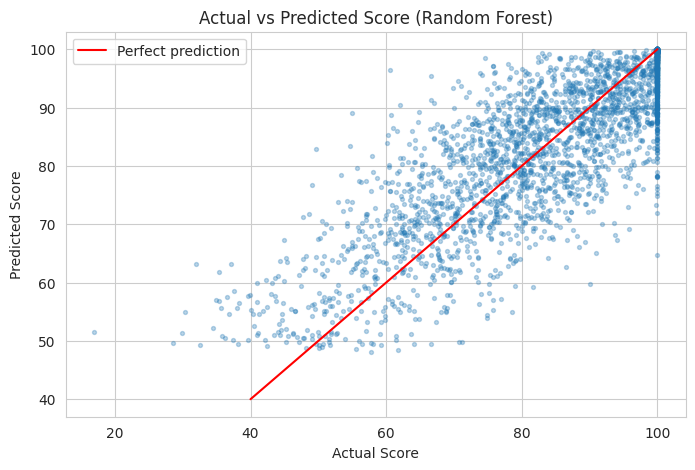

In [62]:
idx = np.random.RandomState(42).choice(len(y_test), 3000, replace=False)

plt.scatter(y_test.values[idx], rf_pred[idx], alpha=0.3, s=8)
plt.plot([40, 100], [40, 100], color="red", label="Perfect prediction")
plt.title("Actual vs Predicted Score (Random Forest)")
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.legend()
plt.show()

**My observation:**
- Points are spread around the red perfect-prediction line, so the model captures the general trend but not each student exactly.
- At actual score 100 the predictions range from about 65 to 100. The cap at 100 hides real differences between top students, so the model cannot separate them.
- For low actual scores (below 60) the model predicts too high, because it pulls predictions toward the average.
- Predictions never go above 100, unlike Linear Regression, which predicted up to 129.7.